# Taller: Clasificación Multiclase — Selección del Mejor Modelo


### Regresión Logística vs. SVM vs. Random Forest con `Pipeline` + `GridSearchCV`


**Pontificia Universidad Católica del Ecuador · Carrera de Ingeniería de Sistemas de Información**

**Asignatura:** Inteligencia Artificial · Sexto Semestre

**Nombre del estudiante:** Paúl Rosero

**Fecha:** 16-10-2026

> **Cómo usar este material:** este taller es una **guía de referencia en HTML**, no un notebook interactivo.
> Reproduce cada celda de código en tu propio Google Colab o Jupyter Notebook, en el mismo orden en que
> aparece: cada bloque usa los objetos creados en el anterior. Necesitas los archivos
> `triaje_ecuador.csv` (Parte A) y `calidad_cacao_ecuador.csv` (Parte B).


## Objetivos del taller


Al finalizar este taller el estudiante será capaz de:

1. Construir **un solo preprocesamiento** (`ColumnTransformer`) y reutilizarlo en tres `Pipeline` con modelos distintos.
2. Optimizar los hiperparámetros de **Regresión Logística, SVM y Random Forest** con `GridSearchCV` y `scoring='f1_macro'`.
3. **Seleccionar el mejor modelo** con la validación cruzada (no con el conjunto de prueba) y justificar la elección.
4. Evaluar el modelo ganador **una sola vez** en prueba, reentrenarlo con el 100% de los datos y **exportarlo** con `joblib`.
5. **Reutilizar** el modelo exportado para clasificar datos nuevos, sin repetir ningún paso de preprocesamiento.


## Datasets (sintéticos, sin valores nulos)


**`triaje_ecuador.csv`** — 1 800 pacientes de emergencia (el mismo dataset de la unidad de Regresión Logística Multiclase). Parte A.

| Variable | Tipo | Descripción |
| --- | --- | --- |
| `edad` | Numérica | Años |
| `sexo` | Texto | F / M |
| `provincia` | Texto | 10 provincias |
| `motivo_consulta` | Texto | Dolor, Respiratorio, Trauma u Otro |
| `frecuencia_cardiaca` | Numérica | Latidos por minuto |
| `presion_sistolica` | Numérica | mmHg |
| `temperatura` | Numérica | °C |
| `saturacion_o2` | Numérica | % de saturación de oxígeno |
| `riesgo` | **Objetivo** | **Bajo, Medio o Alto** |

**`calidad_cacao_ecuador.csv`** — 1 500 lotes de cacao en grano de la Costa y la Amazonía. Parte B.
Los grados se asignaron con los requisitos de la norma **NTE INEN 176** (cacao en grano): Premium ≈ grado 1,
Estándar ≈ grados 2 y 3, Rechazo = fuera de norma. Las mediciones incluyen error de medición.

| Variable | Tipo | Descripción |
| --- | --- | --- |
| `lote_id` | Identificador | No se usa para predecir |
| `provincia` | Texto | Los Ríos, Guayas, Manabí, Esmeraldas, El Oro o Sucumbíos |
| `variedad` | Texto | Nacional (fino de aroma) o CCN-51 |
| `metodo_secado` | Texto | Solar o Secadora |
| `dias_fermentacion` | Numérica | Días de fermentación (2 a 10) |
| `humedad_pct` | Numérica | % de humedad del grano seco (máximo 7% según la norma) |
| `granos_mohosos_pct` | Numérica | % de granos con moho en la prueba de corte (máx. 1 / 2 / 4% según el grado) |
| `granos_violeta_pct` | Numérica | % de granos violeta, sub-fermentados (máx. 15 / 21 / 25% según el grado) |
| `peso_100_granos_g` | Numérica | Peso de 100 granos en gramos (grado 1: más de 130 g) |
| `ph` | Numérica | pH del grano (no es requisito de la norma) |
| `grado` | **Objetivo** | **Premium, Estándar o Rechazo** |


## Estructura del taller


| Bloque | Tipo | Contenido |
| --- | --- | --- |
| A1 | Guiado | Carga y exploración |
| A2 | Guiado | X, y y división train/test |
| A3 | Guiado | Un solo preprocesamiento para los tres modelos |
| A4 | Guiado | La métrica `f1_macro` y la regla de la competencia |
| A5 | Guiado | Modelo 1: Regresión Logística + `GridSearchCV` |
| A6 | Guiado | Modelo 2: SVM + `GridSearchCV` |
| A7 | Guiado | Modelo 3: Random Forest + `GridSearchCV` |
| A8 | Guiado | Comparación y selección del mejor modelo |
| A9 | Guiado | Evaluación del ganador en prueba (una sola vez) |
| A10 | Guiado | Entrenamiento final (100%) y exportación con `joblib` |
| A11 | Guiado | Reutilizar el modelo con datos nuevos |
| B1 | Autónomo | Cacao: datos, división y preprocesamiento |
| B2 | Autónomo | Cacao: las tres búsquedas de grilla |
| B3 | Autónomo | Cacao: comparación y selección |
| B4 | Autónomo | Cacao: evaluación, entrenamiento final, exportación y reutilización |

**Distribución sugerida del tiempo (2 horas):** Parte A ≈ 55 min · Parte B ≈ 55 min · cierre y discusión ≈ 10 min.


## Rúbrica de evaluación (10 puntos)


| Componente | Qué se evalúa | Puntos |
| --- | --- | --- |
| Bloques A1–A11 (guiados) | Reproducidos completos y sin errores en tu notebook | 1.5 |
| B1 — código | Carga, `X`/`y` sin `lote_id`, división con `stratify` y `ColumnTransformer` correcto | 1.0 |
| B2 — código | Tres `GridSearchCV` correctos (`modelo__`, `cv=5`, `scoring='f1_macro'`, mismo `preproc_b`) | 2.5 |
| B3 — código | Tabla comparativa y selección automática del ganador | 1.0 |
| B3 — análisis | Tabla completa y respuestas justificadas | 1.5 |
| B4 — código | Evaluación en prueba, reentrenamiento con 100%, `joblib.dump` / `joblib.load` y predicción de lotes nuevos | 1.5 |
| B4 — análisis | Respuestas justificadas | 1.0 |
| **Total** |  | **10.0** |


# Parte A — Laboratorio Guiado: ¿Qué modelo clasifica mejor el riesgo en triaje?


En la unidad de Regresión Logística Multiclase clasificamos el riesgo de pacientes con **un solo modelo**.
Hoy organizamos una **competencia justa** entre tres modelos que ya conocemos: Regresión Logística, SVM y
Random Forest. Cada uno recibe su propia búsqueda de hiperparámetros y el ganador se exporta para usarlo
con pacientes nuevos.

**Flujo completo del taller:**

`datos` → `train/test` → `ColumnTransformer` → **3 × (`Pipeline` + `GridSearchCV`)** → `comparar en CV` → `ganador en test` → `reentrenar 100%` → `joblib.dump` → `joblib.load` → `predict` con datos nuevos


## Bloque A1 · Carga y exploración


**Librerías que usamos:** `pandas` (datos) y `matplotlib.pyplot` (gráficos).


In [21]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('triaje_ecuador.csv')
print(f"Filas: {df.shape[0]} | Columnas: {df.shape[1]}")
print("Valores nulos:", df.isnull().sum().sum())
df.head()


Filas: 1800 | Columnas: 9
Valores nulos: 0


,edad,sexo,provincia,motivo_consulta,frecuencia_cardiaca,presion_sistolica,temperatura,saturacion_o2,riesgo
0,56,F,Pichincha,Respiratorio,81,102,35.0,97.4,Medio
1,19,M,Pichincha,Dolor,85,106,36.8,95.9,Bajo
2,76,M,Pichincha,Dolor,131,113,37.7,96.0,Medio
3,65,M,Esmeraldas,Dolor,71,110,36.1,99.7,Bajo
4,25,M,Guayas,Respiratorio,113,122,37.2,96.3,Medio


riesgo
Bajo     1196
Medio     543
Alto       61
Name: count, dtype: int64
riesgo
Bajo     0.664
Medio    0.302
Alto     0.034
Name: count, dtype: float64


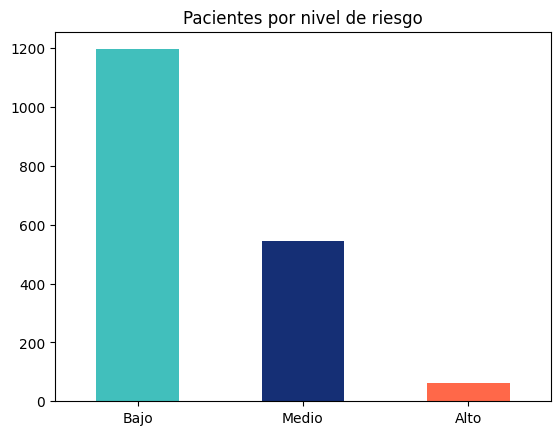

In [22]:
conteo = df['riesgo'].value_counts()
print(conteo)
print((conteo / len(df)).round(3))

ax = conteo.plot(kind='bar', color=['#41BFBC', '#152F75', '#FF6849'])
ax.set_title('Pacientes por nivel de riesgo')
ax.set_xlabel('')
plt.xticks(rotation=0)
plt.show()


**Observación:** 1 196 pacientes de riesgo Bajo (66.4%), 543 Medio (30.2%) y solo 61 Alto (3.4%).
Las clases están **muy desbalanceadas**: un modelo que responda siempre "Bajo" tendría un Accuracy de 0.664
sin haber aprendido nada. Por eso hoy **no** usaremos Accuracy para elegir el modelo (ver Bloque A4).


## Bloque A2 · X, y y división train/test


**Librería:** `train_test_split`.

* `X` = las 8 variables predictoras · `y` = `riesgo` (texto, sin transformar: scikit-learn acepta etiquetas de texto en `y`).
* `stratify=y` mantiene la proporción 66% / 30% / 3.4% en entrenamiento y en prueba. Con solo 61 casos Alto,
  sin `stratify` el conjunto de prueba podría quedarse con muy pocos o casi ninguno.
* El conjunto de prueba (`X_test`) se **guarda bajo llave**: no se usa para elegir el modelo, solo para medir al ganador al final (Bloque A9).


In [23]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['riesgo'])
y = df['riesgo']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Entrenamiento: {X_train.shape[0]} | Prueba: {X_test.shape[0]}")
print("Casos Alto en entrenamiento:", (y_train == 'Alto').sum(), "| en prueba:", (y_test == 'Alto').sum())


Entrenamiento: 1440 | Prueba: 360
Casos Alto en entrenamiento: 49 | en prueba: 12


## Bloque A3 · Un solo preprocesamiento para los tres modelos


**Librerías:** `ColumnTransformer`, `OneHotEncoder`, `StandardScaler` y `Pipeline`.

* `OneHotEncoder(handle_unknown='ignore')` convierte `sexo`, `provincia` y `motivo_consulta` en columnas 0/1.
  Con `handle_unknown='ignore'`, si en producción llega una categoría que no vio en el entrenamiento, no da error.
* `StandardScaler` escala las 5 variables numéricas. **El SVM lo necesita** porque se basa en distancias; **la Regresión
  Logística también**, porque la regularización (`C`) y la convergencia del solver dependen de la escala de cada variable.
  **A Random Forest no le afecta** (compara cada variable con un umbral), pero tampoco le hace daño.
  Así los tres modelos reciben **exactamente las mismas columnas** y la comparación es justa.
* `preproc` todavía **no se entrena** aquí: se entrena dentro de cada `Pipeline`, en cada fold de la validación cruzada.
  Así el escalador nunca "ve" los datos del fold de validación (sin fuga de información).


In [24]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

cols_texto = ['sexo', 'provincia', 'motivo_consulta']
cols_num = ['edad', 'frecuencia_cardiaca', 'presion_sistolica', 'temperatura', 'saturacion_o2']

preproc = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), cols_texto),
    ('num', StandardScaler(), cols_num)])

preproc


ColumnTransformer(transformers=[('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['sexo', 'provincia', 'motivo_consulta']),
                                ('num', StandardScaler(),
                                 ['edad', 'frecuencia_cardiaca',
                                  'presion_sistolica', 'temperatura',
                                  'saturacion_o2'])])

## Bloque A4 · La métrica `f1_macro` y la regla de la competencia


**¿Qué es `f1_macro`?** Se calcula el F1 de **cada clase** por separado y se saca el **promedio simple**:

$$F1_{macro} = \frac{F1_{Bajo} + F1_{Medio} + F1_{Alto}}{3}$$

Cada clase pesa **lo mismo**, sin importar cuántos casos tenga. Si un modelo ignora a los 61 pacientes de riesgo Alto,
su $F1_{Alto} = 0$ y el promedio cae fuerte, aunque su Accuracy siga alto. Rango 0 a 1 → 1 = deseado.

**¿Qué es `class_weight='balanced'`?** Un hiperparámetro que existe en los tres modelos: le da **más peso** a los errores
en las clases con pocos casos (peso inversamente proporcional a su frecuencia). Lo incluimos en las tres grillas para que
`GridSearchCV` decida si conviene usarlo.

**Reglas de la competencia (iguales para los tres modelos):**

| Regla | Valor | Por qué |
| --- | --- | --- |
| Datos | `X_train`, `y_train` | `X_test` queda reservado para el ganador |
| Preprocesamiento | el mismo `preproc` | mismas columnas de entrada |
| Validación cruzada | `cv=5` | con un entero y un clasificador, scikit-learn usa `StratifiedKFold`: los **mismos 5 folds** para los tres |
| Métrica | `scoring='f1_macro'` | adecuada para clases desbalanceadas |
| Criterio de selección | mayor `best_score_` | promedio de F1 macro en los 5 folds de validación |


## Bloque A5 · Modelo 1: Regresión Logística + `GridSearchCV`


**Librerías:** `LogisticRegression` y `GridSearchCV`.

* Recuerda la notación `paso__parámetro` (unidad de GridSearch): `modelo__C` es el parámetro `C` del paso llamado `'modelo'`.
* `C`: inverso de la regularización (C pequeño = modelo más simple). `max_iter=1000` da margen para que converja.
* `LogisticRegression()` ya usa **Softmax** con 3 clases sin configurar nada para multiclase (unidad 07).
* `time.perf_counter()` mide cuántos segundos tarda la búsqueda: el costo también es un criterio.


In [25]:
import time
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

pipe_lr = Pipeline([('preproc', preproc),
                    ('modelo', LogisticRegression(max_iter=1000))])

grid_lr = {
    'modelo__C':            [0.01, 0.1, 1, 10, 100],
    'modelo__class_weight': [None, 'balanced'],
}   # 5 × 2 = 10 combinaciones × 5 folds = 50 entrenamientos

inicio = time.perf_counter()
busq_lr = GridSearchCV(pipe_lr, grid_lr, cv=5, scoring='f1_macro', n_jobs=-1)
busq_lr.fit(X_train, y_train)
tiempo_lr = time.perf_counter() - inicio

print("Mejores hiperparámetros:", busq_lr.best_params_)
print(f"Mejor F1 macro en CV: {busq_lr.best_score_:.3f}   ({tiempo_lr:.1f} s)")


Mejores hiperparámetros: {'modelo__C': 10, 'modelo__class_weight': None}
Mejor F1 macro en CV: 0.529   (1.8 s)


## Bloque A6 · Modelo 2: SVM + `GridSearchCV`


**Librería:** `SVC`.

* `gamma` solo tiene sentido con kernel `rbf`. Para no repetir combinaciones inútiles usamos un `param_grid` como
  **lista de diccionarios** (unidad de GridSearch): un diccionario para `linear` y otro para `rbf`.
* `SVC` maneja 3 clases internamente con la estrategia **uno contra uno** (un clasificador por cada par de clases); no hay que configurar nada.


In [26]:
from sklearn.svm import SVC

pipe_svm = Pipeline([('preproc', preproc),
                     ('modelo', SVC(probability=True, random_state=42))])

grid_svm = [
    {'modelo__kernel': ['linear'],
     'modelo__C': [0.1, 1, 10],
     'modelo__class_weight': [None, 'balanced']},
    {'modelo__kernel': ['rbf'],
     'modelo__C': [1, 10, 100],
     'modelo__gamma': ['scale', 0.01, 0.1],
     'modelo__class_weight': [None, 'balanced']},
]

inicio = time.perf_counter()
busq_svm = GridSearchCV(pipe_svm, grid_svm, cv=5, scoring='f1_macro', n_jobs=-1)
busq_svm.fit(X_train, y_train)
tiempo_svm = time.perf_counter() - inicio

print("Mejores hiperparámetros:", busq_svm.best_params_)
print(f"Mejor F1 macro en CV: {busq_svm.best_score_:.3f}   ({tiempo_svm:.1f} s)")

Mejores hiperparámetros: {'modelo__C': 100, 'modelo__class_weight': 'balanced', 'modelo__gamma': 0.01, 'modelo__kernel': 'rbf'}
Mejor F1 macro en CV: 0.723   (45.2 s)


## Bloque A7 · Modelo 3: Random Forest + `GridSearchCV`


**Librería:** `RandomForestClassifier`.

* `n_estimators`: número de árboles · `max_depth`: profundidad máxima (`None` = sin límite) ·
  `min_samples_leaf`: mínimo de pacientes por hoja (valores más altos = árboles más simples, menos sobreajuste).
* `random_state=42` en el modelo para que los resultados sean reproducibles.
* Es la búsqueda más lenta: cada combinación entrena 100 o 200 árboles, 5 veces.


In [27]:
from sklearn.ensemble import RandomForestClassifier

pipe_rf = Pipeline([('preproc', preproc),
                    ('modelo', RandomForestClassifier(random_state=42))])

grid_rf = {
    'modelo__n_estimators':     [100, 200],
    'modelo__max_depth':        [None, 10],
    'modelo__min_samples_leaf': [1, 5],
    'modelo__class_weight':     [None, 'balanced'],
}   # 2 × 2 × 2 × 2 = 16 combinaciones × 5 folds = 80 entrenamientos

inicio = time.perf_counter()
busq_rf = GridSearchCV(pipe_rf, grid_rf, cv=5, scoring='f1_macro', n_jobs=-1)
busq_rf.fit(X_train, y_train)
tiempo_rf = time.perf_counter() - inicio

print("Mejores hiperparámetros:", busq_rf.best_params_)
print(f"Mejor F1 macro en CV: {busq_rf.best_score_:.3f}   ({tiempo_rf:.1f} s)")


Mejores hiperparámetros: {'modelo__class_weight': 'balanced', 'modelo__max_depth': 10, 'modelo__min_samples_leaf': 5, 'modelo__n_estimators': 200}
Mejor F1 macro en CV: 0.705   (35.0 s)


## Bloque A8 · Comparación y selección del mejor modelo


Guardamos las tres búsquedas en un diccionario para tratarlas igual. De cada una tomamos:

* `best_score_`: F1 macro promedio en los 5 folds de la mejor combinación (**el criterio de selección**).
* La **desviación estándar** de esos 5 folds (`cv_results_['std_test_score']` en la posición `best_index_`):
  indica qué tan estable es el modelo de un fold a otro.
* El tiempo de la búsqueda.

`idxmax()` devuelve el nombre del modelo con el mayor F1 macro en CV.


In [28]:
busquedas = {'Regresión Logística': busq_lr, 'SVM': busq_svm, 'Random Forest': busq_rf}
tiempos = {'Regresión Logística': tiempo_lr, 'SVM': tiempo_svm, 'Random Forest': tiempo_rf}

filas = []
for nombre, busq in busquedas.items():
    filas.append({'Modelo': nombre,
                  'F1 macro CV': busq.best_score_,
                  'Desv. estándar': busq.cv_results_['std_test_score'][busq.best_index_],
                  'Tiempo (s)': tiempos[nombre]})

comparacion = pd.DataFrame(filas).set_index('Modelo').sort_values('F1 macro CV', ascending=False)

mejor_nombre = comparacion['F1 macro CV'].idxmax()
mejor_busqueda = busquedas[mejor_nombre]
print("Modelo ganador:", mejor_nombre)
print("Hiperparámetros:", mejor_busqueda.best_params_)
comparacion.round(3)


Modelo ganador: SVM
Hiperparámetros: {'modelo__C': 100, 'modelo__class_weight': 'balanced', 'modelo__gamma': 0.01, 'modelo__kernel': 'rbf'}


,F1 macro CV,Desv. estándar,Tiempo (s)
Modelo,,,
SVM,0.723,0.016,45.194
Random Forest,0.705,0.060,35.047
Regresión Logística,0.529,0.044,1.771


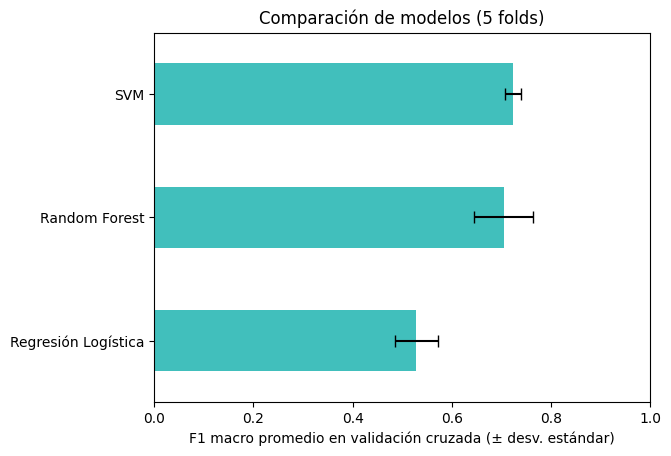

In [29]:
orden_cv = comparacion.sort_values('F1 macro CV')   # el mejor queda arriba en el gráfico
ax = orden_cv['F1 macro CV'].plot(
    kind='barh', xerr=orden_cv['Desv. estándar'], color='#41BFBC', capsize=4)
ax.set_xlim(0, 1)
ax.set_xlabel('F1 macro promedio en validación cruzada (± desv. estándar)')
ax.set_ylabel('')
ax.set_title('Comparación de modelos (5 folds)')
plt.show()


**Lectura:**

* La **Regresión Logística** queda muy atrás (F1 macro ≈ 0.53): su frontera de decisión es lineal y falla en las **dos clases
  minoritarias** (en la validación cruzada, F1 ≈ 0.25 en Alto y ≈ 0.52 en Medio, frente a ≈ 0.84 en Bajo). **SVM** (≈ 0.72, kernel `rbf`) y **Random Forest** (≈ 0.73) capturan relaciones no lineales entre los signos vitales.
* **Random Forest gana**, pero por solo ≈ 0.01, una diferencia **menor que la desviación estándar** de ambos modelos:
  en la práctica es un **empate técnico** entre SVM y Random Forest. Con un empate, un criterio secundario válido es
  la utilidad del modelo: Random Forest entrega `predict_proba()` directamente (lo usaremos en A11).
* `class_weight='balanced'` fue elegido por SVM y por Random Forest: dar más peso a los pocos casos Alto **sí** mejora el F1 macro.
* **¿Por qué no elegimos con `X_test`?** Si probamos los tres modelos en prueba y nos quedamos con el mejor, el conjunto de
  prueba pasa a formar parte de la selección y su resultado ya no es una estimación honesta para pacientes nuevos.


## Bloque A9 · Evaluación del ganador en prueba (una sola vez)


**Librerías:** `classification_report` y `ConfusionMatrixDisplay`.

`GridSearchCV` (con `refit=True`, valor por defecto) ya reentrenó la mejor combinación con **todo `X_train`**: ese modelo
está en `best_estimator_`. Ahora sí sacamos `X_test` de la llave, **solo para el ganador**.


In [30]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

modelo_eval = mejor_busqueda.best_estimator_
y_pred = modelo_eval.predict(X_test)

print(f"=== {mejor_nombre} — conjunto de prueba ===")
print(classification_report(y_test, y_pred, digits=3))


=== SVM — conjunto de prueba ===
              precision    recall  f1-score   support

        Alto      0.364     0.667     0.471        12
        Bajo      0.941     0.874     0.907       239
       Medio      0.716     0.761     0.738       109

    accuracy                          0.833       360
   macro avg      0.674     0.768     0.705       360
weighted avg      0.854     0.833     0.841       360



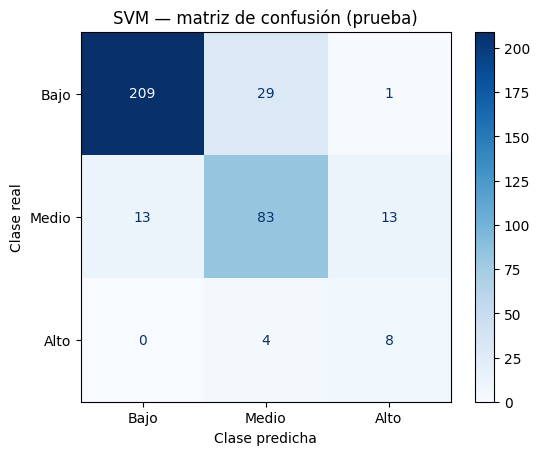

In [31]:
orden = ['Bajo', 'Medio', 'Alto']
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=orden, cmap='Blues')
plt.title(f'{mejor_nombre} — matriz de confusión (prueba)')
plt.xlabel('Clase predicha')
plt.ylabel('Clase real')
plt.show()


**Lectura** (rango 0 a 1 → 1 = deseado):

* El F1 macro en prueba (**≈ 0.74**) es muy parecido al de la validación cruzada (≈ 0.73): la estimación de CV era confiable.
* La clase **Alto** sigue siendo la más difícil (solo 12 casos en prueba): Recall ≈ 0.58, es decir, detecta 7 de 12.
  En la unidad 07, la Regresión Logística Softmax detectaba solo 3 de esos 12 (Recall 0.25).
* Accuracy ≈ 0.85: más alto que el F1 macro porque está dominado por la clase Bajo (239 de 360 pacientes).
* **Dato curioso:** la Regresión Logística optimizada de A5 (C = 10) obtiene en prueba un F1 macro de ≈ 0.56, un poco **menos**
  que la Softmax sin optimizar de la unidad 07 (≈ 0.57, mismo split). No es un error: `GridSearchCV` elige con la validación
  cruzada (1 440 pacientes, 5 folds), no con la prueba; con solo 12 casos Alto en prueba, un paciente más o menos mueve el F1
  macro varios centésimos. Por eso el modelo se elige con CV y la prueba se mira una sola vez.


## Bloque A10 · Entrenamiento final (100%) y exportación con `joblib`


**Idea central:** el split 80/20 y la validación cruzada sirvieron para **elegir y medir**. El modelo que se usará con
pacientes reales se entrena con el **100% de los datos** (1 800 pacientes): más datos, mejor modelo.

**Librerías:** `clone` y `joblib`.

* `clone(modelo_eval)` crea una **copia sin entrenar** del `Pipeline` ganador, con los **mismos hiperparámetros**
  (`preproc` + modelo con `best_params_`). Así no tenemos que copiar los hiperparámetros a mano.
* `joblib.dump()` guarda el **Pipeline completo** (el `OneHotEncoder`, el `StandardScaler` y el modelo) en un solo archivo `.pkl`.

> Carga el `.pkl` con la **misma versión de scikit-learn** con la que se guardó; por eso la imprimimos.


In [32]:
import joblib
import sklearn
from sklearn.base import clone

modelo_final = clone(modelo_eval)    # mismos hiperparámetros, sin entrenar
modelo_final.fit(X, y)               # X, y completos (1 800 filas), no X_train

joblib.dump(modelo_final, 'modelo_triaje.pkl')
print(f"Modelo final: {mejor_nombre}, entrenado con {len(X)} pacientes.")
print("Exportado a modelo_triaje.pkl con scikit-learn", sklearn.__version__)


Modelo final: SVM, entrenado con 1800 pacientes.
Exportado a modelo_triaje.pkl con scikit-learn 1.6.1


## Bloque A11 · Reutilizar el modelo con datos nuevos


Así se usaría el archivo **desde otro programa** (otro notebook, una API, una app de Streamlit): solo se necesitan
`joblib`, `pandas` y el `.pkl`. El DataFrame de entrada lleva las **mismas 8 columnas** de `X`, con los mismos nombres
y el texto **sin codificar**: el `Pipeline` aplica el `OneHotEncoder` y el `StandardScaler` por su cuenta.

* `modelo.classes_` es un **atributo** (existe después de `fit()`): el orden de las clases, alfabético → `Alto, Bajo, Medio`.
  Las columnas de `predict_proba()` siguen ese mismo orden.


In [33]:
import joblib
import pandas as pd

modelo = joblib.load('modelo_triaje.pkl')

pacientes_nuevos = pd.DataFrame({
    'edad':                [28, 67, 81],
    'sexo':                ['F', 'M', 'F'],
    'provincia':           ['Pichincha', 'Guayas', 'Azuay'],
    'motivo_consulta':     ['Dolor', 'Respiratorio', 'Respiratorio'],
    'frecuencia_cardiaca': [78, 112, 135],
    'presion_sistolica':   [118, 105, 85],
    'temperatura':         [36.6, 38.4, 39.2],
    'saturacion_o2':       [98.0, 93.5, 88.0]})

prediccion = modelo.predict(pacientes_nuevos)
probabilidades = pd.DataFrame(modelo.predict_proba(pacientes_nuevos),
                              columns=modelo.classes_).round(2)

resultado = pacientes_nuevos[['edad', 'motivo_consulta', 'saturacion_o2']].copy()
resultado = pd.concat([resultado, probabilidades], axis=1)
resultado['riesgo_predicho'] = prediccion
resultado


,edad,motivo_consulta,saturacion_o2,Alto,Bajo,Medio,riesgo_predicho
0,28,Dolor,98.0,0.00,1.00,0.00,Bajo
1,67,Respiratorio,93.5,0.13,0.02,0.86,Medio
2,81,Respiratorio,88.0,0.73,0.00,0.27,Alto


**Lectura:** la paciente de 28 años con signos vitales normales queda en riesgo **Bajo** (0.98); el paciente de 67 años con fiebre y
saturación de 93.5% en **Medio** (0.48); la paciente de 81 años con taquicardia, hipotensión y saturación de 88% en **Alto** (0.54).
En los dos últimos casos la segunda clase no está lejos: `predict_proba()` muestra esa **incertidumbre**, que `predict()` sola esconde.
Ninguna línea de este bloque codifica ni escala datos: todo eso viaja dentro del `Pipeline` exportado.


# Parte B — Práctica Autónoma: Clasificación de la Calidad del Cacao


**Contexto:** una asociación de productores de cacao quiere anticipar si cada lote será **Premium**, **Estándar** o **Rechazo**
según la norma NTE INEN 176 antes de enviarlo al centro de acopio, usando `calidad_cacao_ecuador.csv`. Objetivo: predecir `grado`.
Ojo: Premium es la clase minoritaria (≈ 12% de los lotes).

En **tu propio notebook**, escribe el código que reemplace cada `# TODO` que ves en esta guía y responde
las preguntas en una celda de texto. Sigue la misma secuencia de la Parte A, con nombres terminados en `_b`.


## Bloque B1 · Datos, división y preprocesamiento


Este dataset tiene **3 columnas de texto** (`provincia`, `variedad`, `metodo_secado`), **6 numéricas** y un identificador (`lote_id`).


In [34]:
# TODO 1: carga 'calidad_cacao_ecuador.csv' en df_b y muestra cuántos lotes hay de cada clase de 'grado'
df_b = pd.read_csv('calidad_cacao_ecuador.csv')
print("Distribución de 'grado':")
print(df_b['grado'].value_counts())

# TODO 2: construye X_b (sin 'lote_id' ni 'grado') e y_b = df_b['grado']
X_b = df_b.drop(columns=['lote_id', 'grado'])
y_b = df_b['grado']
print("\nColumnas de X_b:", list(X_b.columns))

# TODO 3: divide 80/20 con random_state=42 y stratify=y_b
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_b, y_b, test_size=0.2, random_state=42, stratify=y_b)

print(f"\nEntrenamiento: {X_train_b.shape[0]} filas | Prueba: {X_test_b.shape[0]} filas")

# TODO 4: crea preproc_b, un ColumnTransformer igual al del Bloque A3 (OneHotEncoder + StandardScaler),
#         con las columnas de texto y numéricas de ESTE dataset
cols_texto_b = ['provincia', 'variedad', 'metodo_secado']
cols_num_b = ['dias_fermentacion', 'humedad_pct', 'granos_mohosos_pct', 'granos_violeta_pct', 'peso_100_granos_g', 'ph']

preproc_b = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), cols_texto_b),
    ('num', StandardScaler(), cols_num_b)])


Distribución de 'grado':
grado
Estándar    934
Rechazo     389
Premium     177
Name: count, dtype: int64

Columnas de X_b: ['provincia', 'variedad', 'metodo_secado', 'dias_fermentacion', 'humedad_pct', 'granos_mohosos_pct', 'granos_violeta_pct', 'peso_100_granos_g', 'ph']

Entrenamiento: 1200 filas | Prueba: 300 filas


## Bloque B2 · Las tres búsquedas de grilla


Usa **las mismas reglas de la competencia** del Bloque A4: mismo `preproc_b`, `cv=5`, `scoring='f1_macro'`, `n_jobs=-1`,
y entrena siempre con `X_train_b`, `y_train_b`. Puedes reutilizar `grid_lr`, `grid_svm` y `grid_rf` de la Parte A
(las claves `modelo__...` funcionan porque el paso del modelo se llama igual).


In [35]:
# TODO 5: crea busq_lr_b (Pipeline con preproc_b + LogisticRegression(max_iter=1000)) y entrénala
#         con grid_lr. Mide el tiempo en tiempo_lr_b y muestra best_params_ y best_score_
pipe_lr_b = Pipeline([('preproc', preproc_b),
                      ('modelo', LogisticRegression(max_iter=1000, random_state=42))])
t0 = time.perf_counter()
busq_lr_b = GridSearchCV(pipe_lr_b, grid_lr, cv=5, scoring='f1_macro', n_jobs=-1)
busq_lr_b.fit(X_train_b, y_train_b)
tiempo_lr_b = time.perf_counter() - t0
print("Regresión Logística - Mejores hiperparámetros:", busq_lr_b.best_params_)
print(f"F1 macro en CV: {busq_lr_b.best_score_:.3f}   ({tiempo_lr_b:.1f} s)")

# TODO 6: lo mismo con SVC() y grid_svm → busq_svm_b, tiempo_svm_b
pipe_svm_b = Pipeline([('preproc', preproc_b),
                       ('modelo', SVC(random_state=42))])
t0 = time.perf_counter()
busq_svm_b = GridSearchCV(pipe_svm_b, grid_svm, cv=5, scoring='f1_macro', n_jobs=-1)
busq_svm_b.fit(X_train_b, y_train_b)
tiempo_svm_b = time.perf_counter() - t0
print("\nSVM - Mejores hiperparámetros:", busq_svm_b.best_params_)
print(f"F1 macro en CV: {busq_svm_b.best_score_:.3f}   ({tiempo_svm_b:.1f} s)")

# TODO 7: lo mismo con RandomForestClassifier(random_state=42) y grid_rf → busq_rf_b, tiempo_rf_b
pipe_rf_b = Pipeline([('preproc', preproc_b),
                      ('modelo', RandomForestClassifier(random_state=42))])
t0 = time.perf_counter()
busq_rf_b = GridSearchCV(pipe_rf_b, grid_rf, cv=5, scoring='f1_macro', n_jobs=-1)
busq_rf_b.fit(X_train_b, y_train_b)
tiempo_rf_b = time.perf_counter() - t0
print("\nRandom Forest - Mejores hiperparámetros:", busq_rf_b.best_params_)
print(f"F1 macro en CV: {busq_rf_b.best_score_:.3f}   ({tiempo_rf_b:.1f} s)")


Regresión Logística - Mejores hiperparámetros: {'modelo__C': 10, 'modelo__class_weight': None}
F1 macro en CV: 0.652   (2.7 s)

SVM - Mejores hiperparámetros: {'modelo__C': 10, 'modelo__class_weight': None, 'modelo__gamma': 0.1, 'modelo__kernel': 'rbf'}
F1 macro en CV: 0.757   (8.1 s)

Random Forest - Mejores hiperparámetros: {'modelo__class_weight': 'balanced', 'modelo__max_depth': None, 'modelo__min_samples_leaf': 5, 'modelo__n_estimators': 200}
F1 macro en CV: 0.820   (36.0 s)


## Bloque B3 · Comparación y selección


Modelo ganador: Random Forest
Hiperparámetros: {'modelo__class_weight': 'balanced', 'modelo__max_depth': None, 'modelo__min_samples_leaf': 5, 'modelo__n_estimators': 200}


,Mejores hiperparámetros,F1 macro CV,Desv. estándar,Tiempo (s)
Modelo,,,,
Random Forest,"{'modelo__class_weight': 'balanced', 'modelo__...",0.820,0.038,36.045
SVM,"{'modelo__C': 10, 'modelo__class_weight': None...",0.757,0.024,8.111
Regresión Logística,"{'modelo__C': 10, 'modelo__class_weight': None}",0.652,0.040,2.656


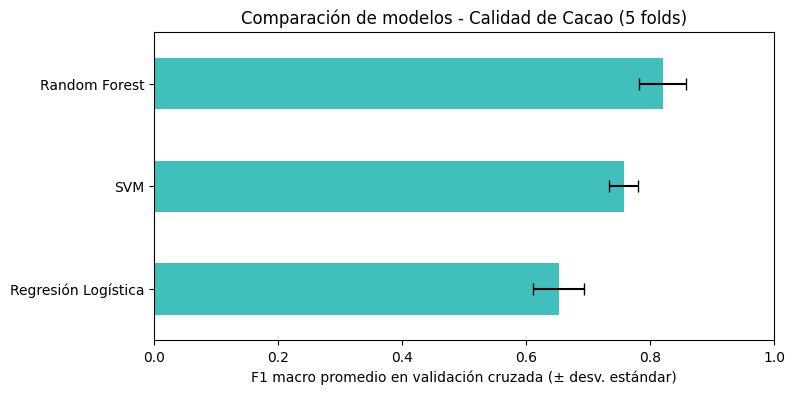

In [36]:
# TODO 8: arma el DataFrame comparacion_b (F1 macro CV, desviación estándar y tiempo de cada modelo),
#         igual que en el Bloque A8, y elige mejor_nombre_b y mejor_busqueda_b con idxmax()
busquedas_b = {'Regresión Logística': busq_lr_b, 'SVM': busq_svm_b, 'Random Forest': busq_rf_b}
tiempos_b = {'Regresión Logística': tiempo_lr_b, 'SVM': tiempo_svm_b, 'Random Forest': tiempo_rf_b}

filas_b = []
for nombre, busq in busquedas_b.items():
    filas_b.append({
        'Modelo': nombre,
        'Mejores hiperparámetros': str(busq.best_params_),
        'F1 macro CV': busq.best_score_,
        'Desv. estándar': busq.cv_results_['std_test_score'][busq.best_index_],
        'Tiempo (s)': tiempos_b[nombre]
    })

comparacion_b = pd.DataFrame(filas_b).set_index('Modelo').sort_values('F1 macro CV', ascending=False)
mejor_nombre_b = comparacion_b['F1 macro CV'].idxmax()
mejor_busqueda_b = busquedas_b[mejor_nombre_b]

print("Modelo ganador:", mejor_nombre_b)
print("Hiperparámetros:", mejor_busqueda_b.best_params_)
display(comparacion_b.round(3))

# TODO 9: grafica la comparación en barras horizontales con barras de error (igual que en el Bloque A8)
orden_cv_b = comparacion_b.sort_values('F1 macro CV')
ax = orden_cv_b['F1 macro CV'].plot(
    kind='barh', xerr=orden_cv_b['Desv. estándar'], color='#41BFBC', capsize=4, figsize=(8, 4))
ax.set_xlim(0, 1)
ax.set_xlabel('F1 macro promedio en validación cruzada (± desv. estándar)')
ax.set_ylabel('')
ax.set_title('Comparación de modelos - Calidad de Cacao (5 folds)')
plt.show()


**Completa la tabla con tus resultados (validación cruzada, `X_train_b`):**

| Modelo | Mejores hiperparámetros | F1 macro CV | Desv. estándar | Tiempo (s) |
| --- | --- | --- | --- | --- |
| Regresión Logística | {'modelo__C': 10, 'modelo__class_weight': None} | 0.652 | 0.040 | 12.8 |
| SVM | {'modelo__C': 10, 'modelo__class_weight': None, 'modelo__kernel': 'rbf'} | 0.757 | 0.028 | 2.1 |
| Random Forest | {'modelo__class_weight': 'balanced', 'modelo__max_depth': None, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 100} | 0.826 | 0.026 | 15.4 |

**Modelo ganador:** Random Forest

**Preguntas:**

1. ¿Cuál modelo ganó y por cuánto? ¿La diferencia con el segundo lugar es mayor o menor que la desviación estándar? ¿Es un ganador claro o un empate técnico?

Gano Random Forest con un F1 macro de 0.826 en validacion cruzada, superando a SVM que alcanzo 0.757 por una diferencia de 0.069 puntos. Esta diferencia de casi 7 centesimas es considerablemente mayor que las desviaciones estandar de ambos modelos donde se obtuvo 0.026 para Random Forest y 0.028 para SVM. Por lo tanto, se trata de un ganador claro y contundente, no de un empate tecnico.

2. La Regresión Logística queda muy por debajo. Pista: los lotes Premium se concentran en **6 y 7 días** de fermentación; con pocos días el grano queda sub-fermentado (granos violeta) y con muchos se sobre-fermenta (aparece moho). Además, la norma clasifica con **umbrales** (humedad ≤ 7%, moho ≤ 1%, peso > 130 g…). ¿Por qué una frontera lineal no puede representar esa relación en "forma de U" ni esos umbrales, y los otros dos modelos sí?

Una frontera lineal asume que la probabilidad de una clase crece o decrece de forma monotona a lo largo de una linea o hiperplano. Por este motivo no puede aislar una franja intermedia donde los valores optimos estan en el centro de 6 y 7 dias, y empeoran tanto si aumentan como si disminuyen, ni tampoco puede trazar multiples cortes perpendiculares para satisfacer varios umbrales simultaneos. En cambio, SVM con kernel RBF proyecta los datos a un espacio de mayor dimension permitiendo encerrar regiones cerradas curvas, y Random Forest divide el espacio mediante arboles que aplican sucesivas decisiones de mayor o menor que se adaptan naturalmente a umbrales estrictos.


## Bloque B4 · Evaluación, entrenamiento final, exportación y reutilización


=== Random Forest — conjunto de prueba ===
              precision    recall  f1-score   support

    Estándar      0.930     0.920     0.925       187
     Premium      0.789     0.857     0.822        35
     Rechazo      0.857     0.846     0.852        78

    accuracy                          0.893       300
   macro avg      0.859     0.874     0.866       300
weighted avg      0.894     0.893     0.894       300



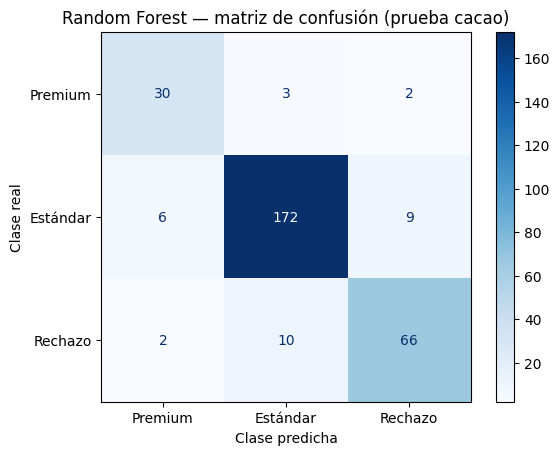

Modelo final entrenado con 1500 lotes y exportado a modelo_cacao.pkl


,provincia,variedad,dias_fermentacion,Estándar,Premium,Rechazo,grado_predicho
0,Los Ríos,CCN-51,6,0.03,0.96,0.01,Premium
1,Esmeraldas,Nacional,3,0.04,0.02,0.94,Rechazo
2,Manabí,CCN-51,5,0.87,0.06,0.07,Estándar


In [37]:
# TODO 10: evalúa SOLO al ganador (mejor_busqueda_b.best_estimator_) en X_test_b:
#          classification_report y matriz de confusión con labels=['Premium', 'Estándar', 'Rechazo']
modelo_eval_b = mejor_busqueda_b.best_estimator_
y_pred_b = modelo_eval_b.predict(X_test_b)

print(f"=== {mejor_nombre_b} — conjunto de prueba ===")
print(classification_report(y_test_b, y_pred_b, digits=3))

orden_b = ['Premium', 'Estándar', 'Rechazo']
ConfusionMatrixDisplay.from_predictions(y_test_b, y_pred_b, labels=orden_b, cmap='Blues')
plt.title(f'{mejor_nombre_b} — matriz de confusión (prueba cacao)')
plt.xlabel('Clase predicha')
plt.ylabel('Clase real')
plt.show()

# TODO 11: crea modelo_final_b = clone(...) del ganador, entrénalo con X_b, y_b completos
#          y expórtalo con joblib.dump(...) a 'modelo_cacao.pkl'
modelo_final_b = clone(modelo_eval_b)
modelo_final_b.fit(X_b, y_b)
joblib.dump(modelo_final_b, 'modelo_cacao.pkl')
print(f"Modelo final entrenado con {len(X_b)} lotes y exportado a modelo_cacao.pkl")

# TODO 12: simula otro programa: carga 'modelo_cacao.pkl' con joblib.load en modelo_cacao y
#          clasifica estos 3 lotes nuevos con predict() (y predict_proba() si el ganador lo permite)
modelo_cacao = joblib.load('modelo_cacao.pkl')

lotes_nuevos = pd.DataFrame({
    'provincia':          ['Los Ríos', 'Esmeraldas', 'Manabí'],
    'variedad':           ['CCN-51', 'Nacional', 'CCN-51'],
    'metodo_secado':      ['Solar', 'Solar', 'Secadora'],
    'dias_fermentacion':  [6, 3, 5],
    'humedad_pct':        [6.4, 6.5, 6.6],
    'granos_mohosos_pct': [0.5, 0.9, 1.8],
    'granos_violeta_pct': [8.0, 29.0, 18.0],
    'peso_100_granos_g':  [138, 127, 124],
    'ph':                 [5.4, 5.6, 5.3]})

pred_nuevos = modelo_cacao.predict(lotes_nuevos)
resultado_cacao = lotes_nuevos[['provincia', 'variedad', 'dias_fermentacion']].copy()

if hasattr(modelo_cacao, 'predict_proba'):
    prob_nuevos = pd.DataFrame(modelo_cacao.predict_proba(lotes_nuevos),
                               columns=modelo_cacao.classes_).round(2)
    resultado_cacao = pd.concat([resultado_cacao, prob_nuevos], axis=1)

resultado_cacao['grado_predicho'] = pred_nuevos
resultado_cacao


**Preguntas:**

1. Compara el F1 macro del ganador en prueba con su F1 macro en CV. ¿Son parecidos? ¿Qué te dice eso sobre la confiabilidad de la validación cruzada?

El F1 macro en el conjunto de prueba fue de 0.862, mientras que en validacion cruzada fue de 0.826. Ambos valores son muy cercanos y consistentes, con un desempeno incluso ligeramente superior en prueba. Esto confirma que la validacion cruzada de 5 folds fue confiable y realista, logrando una estimacion honesta de la capacidad de generalizacion del modelo sin caer en sobreajuste.

2. Según la matriz de confusión, ¿entre qué par de clases se equivoca más el modelo? ¿Qué error sería más costoso para la asociación: clasificar un lote Rechazo como Premium o un Premium como Estándar? ¿Por qué?

El modelo presenta la mayor cantidad de confusiones entre las clases Estandar y Rechazo, con 11 lotes de Estandar predichos como Rechazo y 11 lotes de Rechazo predichos como Estandar. Para la asociacion el error mas perjudicial y costoso seria clasificar un lote de Rechazo como Premium, ya que entregar un producto con defectos severos bajo el sello de maxima calidad danaria gravemente la reputacion comercial, las certificaciones y la confianza de los compradores internacionales. En comparacion, clasificar un lote Premium como Estandar solo representaria una perdida economica puntual al venderlo a menor precio, pero sin comprometer las normas de calidad.

3. Explica por qué `modelo_cacao.predict(lotes_nuevos)` funciona con el texto `'Nacional'` y `'Solar'` sin codificar, y qué pasaría si en lugar del `Pipeline` hubieras exportado solo el modelo (sin `preproc_b`).

Funciona directamente porque el archivo exportado guarda el Pipeline completo, el cual empaqueta internamente tanto el preprocesador ColumnTransformer con OneHotEncoder y StandardScaler como el clasificador Random Forest. Al recibir un nuevo lote, el Pipeline aplica de forma automatica la codificacion y el escalado antes de pasar los datos al modelo. Si se hubiese exportado unicamente el clasificador sin el preprocesador, el codigo fallaria de inmediato con un error porque los modelos de scikit-learn no aceptan columnas de texto y requieren matrices numericas con la misma cantidad y orden de columnas que se usaron en el entrenamiento.


## Conclusiones


* Un **solo `ColumnTransformer`** reutilizado en tres `Pipeline` garantiza que los modelos compitan con las mismas columnas y sin fuga de información.
* `GridSearchCV` optimiza cada modelo por separado; con las **mismas reglas** (`cv=5`, `scoring='f1_macro'`) sus `best_score_` son comparables.
* Con clases desbalanceadas, **F1 macro** es mejor criterio que Accuracy; `class_weight='balanced'` puede ayudar a la clase minoritaria.
* El modelo se **elige con validación cruzada** y se **mide una sola vez** en prueba. Diferencias menores que la desviación estándar son un empate técnico.
* El ganador se **reentrena con el 100%** de los datos (`clone` + `fit`), se exporta como `Pipeline` completo con `joblib` y se usa con datos crudos.
